# 01 · Preprocessing — Wang 2019 Glioblastoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, remove detached islands, and resolve the
manifold into its transcriptional compartments. Glioblastoma malignant cells carry
strong per-patient CNV structure, so batch integration is the central Gate-1 question
here. Wang et al. provide **no cell-cycle annotation** (`cell_cycle_phase` empty,
`g1s_score`/`g2m_score` all-NaN), so — unlike the head-and-neck / colorectal reference
runs that used the publication's phase calls — we **derive** a cell-cycle score from
Tirosh S/G2M gene sets to check that proliferation does not confound the developmental
axis. Every tunable choice is *derived from this dataset*, not inherited. Deliverable:
`processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Wang2019_Brain | category: Brain


### Load malignant compartment
Wang et al. annotate cell type directly; we take their `Malignant` calls. Variable
names are made unique (the 10x gene table has a few duplicated symbols).

In [3]:
adata = load_CCCA_adata(pth_in)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Wang2019_Brain
Done.
full atlas: (16317, 33545)
malignant: (9916, 33545) | samples: 10
expression: X max 7.51 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude. Rather than a round-number
cut, we find the largest **multiplicative** cliff in the sorted counts and cut at its
geometric mean — the natural separatrix between tumour-bearing samples and spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [2732 2492 1293 1112  938  687  396  143   85   38]
largest gap: 396 -> 143 (ratio 2.77)
derived threshold (geometric mean across the gap) = 237
kept 7/10 samples -> 9650 cells


### Derive a cell-cycle score (Tirosh S / G2M)
Wang 2019 ships no usable cycle annotation, so we score the canonical Tirosh et al.
S-phase and G2/M gene sets with `score_genes_cell_cycle`. `cyc_score = max(S, G2M)` is a
single proliferation scalar used later to test whether pseudotime is developmental or
merely a proliferation gradient (the Kürten lobe-identity fork).

In [5]:
S_GENES = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7',
 'DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2',
 'UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM',
 'CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
G2M_GENES = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2',
 'CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB',
 'BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK',
 'CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA',
 'PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sg = [g for g in S_GENES if g in adata.var_names]; gg = [g for g in G2M_GENES if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=sg, g2m_genes=gg)
adata.obs['cyc_score'] = adata.obs[['S_score','G2M_score']].max(axis=1)
print(f'cell-cycle genes present: S={len(sg)}/{len(S_GENES)} G2M={len(gg)}/{len(G2M_GENES)}')
print('phase calls:', adata.obs['phase'].value_counts().to_dict())

cell-cycle genes present: S=42/42 G2M=54/54
phase calls: {'G1': 7777, 'G2M': 1051, 'S': 822}


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing):
we take the strongest integration past which mixing plateaus. **PC count = 30**: the
chord-elbow of the scree lands at 8 here, but the Chen 2020 calibration flagged the
chord-elbow as *over-cutting* (6 PCs forced a patient-segregated read); the structured
variance shoulder extends to ~PC30 and the 10x precedents run 20–40, so 30 is used and
documented rather than the bare elbow. UMAP spread 1.3 follows the 10x precedents.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

# scree: chord-elbow vs chosen n_pcs (documented divergence)
vr = adata.uns['pca']['variance_ratio']
x = np.arange(len(vr)); x0,y0,x1,y1 = x[0],vr[0],x[-1],vr[-1]
d = np.abs((y1-y0)*x-(x1-x0)*vr+x1*y0-y1*x0)/np.hypot(y1-y0,x1-x0)
elbow = int(d.argmax())+1
N_PCS = 30
print(f'chord-elbow n_pcs = {elbow} (over-cuts; Chen2020 lesson) -> using n_pcs = {N_PCS}')

# theta sweep: same-sample neighbour fraction (lower = better batch mixing)
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:N_PCS])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:N_PCS])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2113
chord-elbow n_pcs = 8 (over-cuts; Chen2020 lesson) -> using n_pcs = 30
same-sample neighbour fraction | pre-Harmony 0.991 | sweep {2: 0.788, 5: 0.671, 10: 0.634}
selected theta = 10 (mixing plateaus; strongest integration without collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop
any cell outside the main connected component — stripping physically detached specks
while keeping the continuous manifold body.

In [7]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 16 cells in 1 detached islands


### Compartment resolution + labelling (data-driven)
Low-resolution Leiden (res=0.15) resolves the manifold into transcriptional
compartments. We characterise each *by biology* — its dominant 3CA meta-program
(`mp_top`, which recovers the Neftel GBM hierarchy: NPC/OPC, Astrocyte-like, MES-like,
Oligo-progenitor), its cycling fraction, and its developmental means. Whether the
trajectory spans all compartments or must be scoped to one is decided in 02 from the
signature geography, not assumed here.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
prof = adata.obs.groupby('lobe', observed=True).agg(
    n=('sample','size'), cycling_frac=('cycling','mean'), cyc=('cyc_score','mean'))
adata.obs['mp_top'] = adata.obs['mp_top'].astype(str)
top_mp = (adata.obs.groupby('lobe', observed=True)['mp_top']
          .agg(lambda s: s[s!='nan'].value_counts().index[0] if (s!='nan').any() else 'nan'))
prof['top_meta_program'] = top_mp
print('compartments (Leiden res=0.15):')
print(prof.round(3).to_string())
adata.obs['compartment'] = adata.obs['lobe'].astype(str)

compartments (Leiden res=0.15):
         n  cycling_frac    cyc  top_meta_program
lobe                                             
0     2172         0.176 -0.026        Astrocytes
1     2869         0.230 -0.023           Hypoxia
2     4593         0.181 -0.016  Oligo Progenitor


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. GBM malignant
cells carry private CNVs, so we read Gate 1 on the regenerated embedding itself (below),
corroborated by (i) the same-sample-neighbour-fraction drop under Harmony and (ii) an
iLISI neighbourhood-mixing index — never a single scalar alone (Kürten §1 rule).

In [9]:
def _ilisi(rep, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k).fit(rep).kneighbors(rep, return_distance=False)
    codes = pd.Categorical(labels).codes; B = codes.max()+1
    out = np.empty(len(labels))
    for i in range(len(labels)):
        p = np.bincount(codes[nn[i]], minlength=B)/k
        out[i] = 1.0/np.sum(p**2)
    return out.mean()
nb_ = adata.obs['sample'].nunique()
il_pre = _ilisi(adata.obsm['X_pca'][:,:30], adata.obs['sample'].values)
il_post = _ilisi(adata.obsm['X_pca_harmony'][:,:30], adata.obs['sample'].values)
print(f'{nb_} samples on one connected manifold (islands stripped above)')
print(f'iLISI (neighbourhood sample diversity, max={nb_}): pre-Harmony {il_pre:.2f} -> post {il_post:.2f}')
print('each compartment contains multiple samples:')
print(pd.crosstab(adata.obs['compartment'], adata.obs['sample']).astype(bool).sum(1).to_dict(),
      '(distinct samples per compartment)')
print('Gate 1 read is made on the regenerated embedding (samples.pdf) — see below.')

7 samples on one connected manifold (islands stripped above)
iLISI (neighbourhood sample diversity, max=7): pre-Harmony 1.01 -> post 2.00
each compartment contains multiple samples:
{'0': 7, '1': 7, '2': 7} (distinct samples per compartment)
Gate 1 read is made on the regenerated embedding (samples.pdf) — see below.


### Save processed data

In [10]:
def _clean_obs(ad):
    # Wang ships empty NaN-object obs cols (g1s_score,g2m_score,cell_cycle_phase) that
    # h5py cannot serialize; coerce numeric-looking cols to float, others to str.
    for c in ad.obs.columns:
        col = ad.obs[c]
        if col.dtype == object or str(col.dtype) == 'category':
            num = pd.to_numeric(col, errors='coerce')
            if num.notna().sum() > 0 and num.notna().sum() >= col.notna().sum():
                ad.obs[c] = num.astype(float)
            else:
                ad.obs[c] = col.astype(str)
    return ad
adata = _clean_obs(adata)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9634, 26409)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, colour = sample.
Intermixing of colours across the manifold is the Gate-1 batch-integration evidence.
The GBM manifold is a compact cloud (not an elongated strip), so no orientation
transform is applied to this categorical panel.

saved samples.pdf | cells: 9634


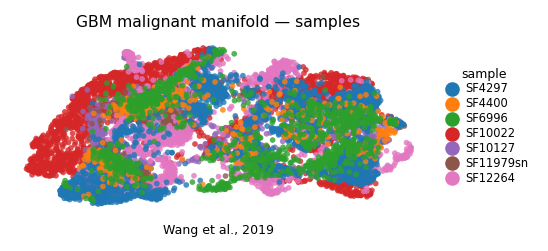

In [11]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('GBM malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])